In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import warnings 
warnings.filterwarnings("ignore")

In [2]:
df=pd.read_csv("A_B_testing_dataset.csv")

In [3]:
df.head()

,date_of_campaign,facebook_ad_campaign,facebook_ad_views,facebook_ad_clicks,facebook_ad_conversions,facebook_cost_per_ad,facebook_ctr,facebook_conversion_rate,facebook_cost_per_click,adword_ad_campaign,adword_ad_views,adword_ad_clicks,adword_ad_conversions,adword_cost_per_ad,adword_ctr,adword_conversion_rate,adword_cost_per_click
0,2021-12-22,FACEBOOK AD,3172,62,14,141,1.95,22.58,2.27,ADWORD AD,5754,64,9,177,1.11,14.06,2.77
1,2021-12-24,FACEBOOK AD,3211,38,9,186,1.18,23.68,4.89,ADWORD AD,4954,73,6,54,1.47,8.22,0.74
2,2021-12-25,FACEBOOK AD,1936,53,15,66,2.74,28.30,1.25,ADWORD AD,4702,38,9,187,0.81,23.68,4.92
3,2021-12-25,FACEBOOK AD,1194,45,9,71,3.77,20.00,1.58,ADWORD AD,3718,58,3,161,1.56,5.17,2.78
4,2021-12-26,FACEBOOK AD,2479,44,12,174,1.77,27.27,3.95,ADWORD AD,5562,63,4,162,1.13,6.35,2.57


In [4]:
df.shape

(1000, 17)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   date_of_campaign          1000 non-null   object 
 1   facebook_ad_campaign      1000 non-null   object 
 2   facebook_ad_views         1000 non-null   int64  
 3   facebook_ad_clicks        1000 non-null   int64  
 4   facebook_ad_conversions   1000 non-null   int64  
 5   facebook_cost_per_ad      1000 non-null   int64  
 6   facebook_ctr              1000 non-null   float64
 7   facebook_conversion_rate  1000 non-null   float64
 8   facebook_cost_per_click   1000 non-null   float64
 9   adword_ad_campaign        1000 non-null   object 
 10  adword_ad_views           1000 non-null   int64  
 11  adword_ad_clicks          1000 non-null   int64  
 12  adword_ad_conversions     1000 non-null   int64  
 13  adword_cost_per_ad        1000 non-null   int64  
 14  adword_ct

In [6]:
df.describe()

,facebook_ad_views,facebook_ad_clicks,facebook_ad_conversions,facebook_cost_per_ad,facebook_ctr,facebook_conversion_rate,facebook_cost_per_click,adword_ad_views,adword_ad_clicks,adword_ad_conversions,adword_cost_per_ad,adword_ctr,adword_conversion_rate,adword_cost_per_click
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,2152.031000,44.196000,11.975000,156.610000,2.28316,32.696080,4.310500,4771.438000,60.128000,5.933000,124.741000,1.280950,10.807510,2.265540
std,661.982166,16.833328,4.298471,54.918904,1.20670,20.570796,2.751582,598.647684,17.047822,2.011606,43.809053,0.402492,5.205133,1.101846
min,1050.000000,15.000000,5.000000,60.000000,0.49000,6.850000,0.960000,3715.000000,31.000000,3.000000,50.000000,0.540000,3.370000,0.580000
25%,1600.250000,30.000000,8.000000,110.000000,1.36750,18.052500,2.337500,4258.250000,45.000000,4.000000,86.000000,0.940000,6.970000,1.470000
50%,2123.500000,44.500000,12.000000,156.000000,2.07000,27.120000,3.600000,4808.500000,60.000000,6.000000,124.000000,1.260000,9.720000,2.030000
75%,2706.250000,58.000000,16.000000,205.000000,2.92250,41.880000,5.610000,5300.750000,75.000000,8.000000,163.000000,1.570000,13.485000,2.802500
max,3320.000000,73.000000,19.000000,250.000000,6.86000,118.750000,16.530000,5754.000000,89.000000,9.000000,200.000000,2.370000,29.030000,6.190000


In [7]:
# converting date to datetine
df["date_of_campaign"] = pd.to_datetime(df["date_of_campaign"])

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   date_of_campaign          1000 non-null   datetime64[ns]
 1   facebook_ad_campaign      1000 non-null   object        
 2   facebook_ad_views         1000 non-null   int64         
 3   facebook_ad_clicks        1000 non-null   int64         
 4   facebook_ad_conversions   1000 non-null   int64         
 5   facebook_cost_per_ad      1000 non-null   int64         
 6   facebook_ctr              1000 non-null   float64       
 7   facebook_conversion_rate  1000 non-null   float64       
 8   facebook_cost_per_click   1000 non-null   float64       
 9   adword_ad_campaign        1000 non-null   object        
 10  adword_ad_views           1000 non-null   int64         
 11  adword_ad_clicks          1000 non-null   int64         
 12  adword_ad_conversions

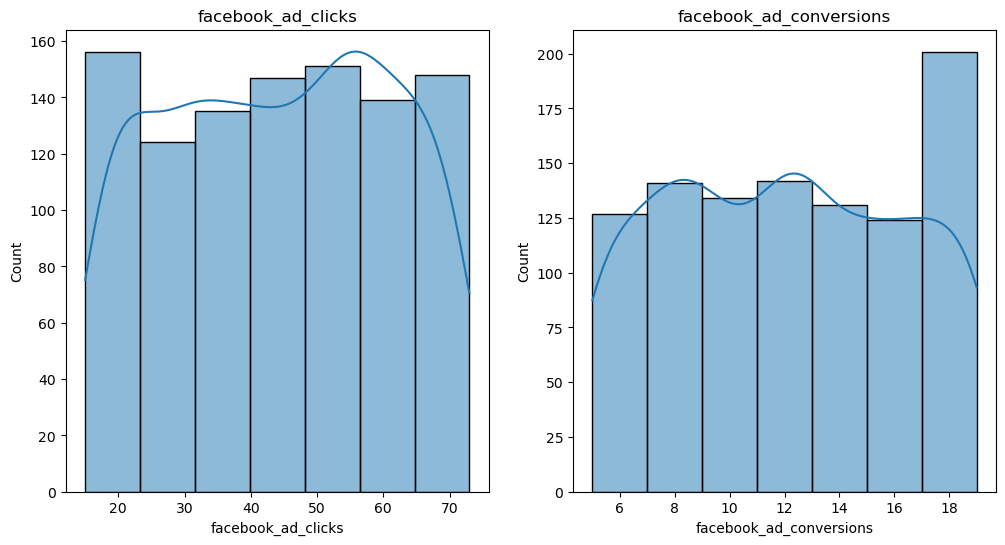

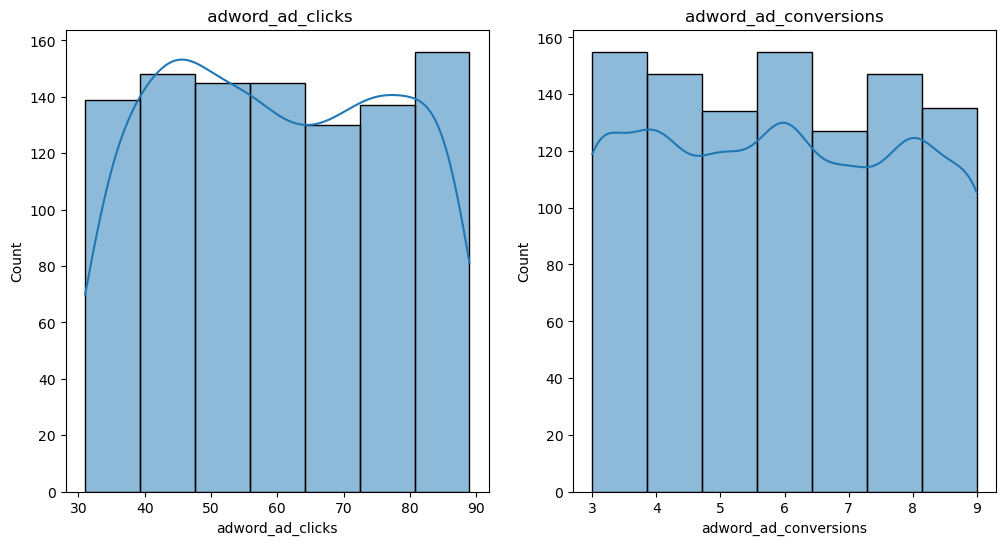

In [9]:
# Comparing camaign conversions
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title("facebook_ad_clicks")
sns.histplot(df["facebook_ad_clicks"],bins=7,edgecolor="k",kde=True)
plt.subplot(1,2,2)
plt.title("facebook_ad_conversions")
sns.histplot(df["facebook_ad_conversions"],bins=7,edgecolor="k",kde=True)
plt.show()

plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title(" adword_ad_clicks")
sns.histplot(df["adword_ad_clicks"],bins=7,edgecolor="k",kde=True)
plt.subplot(1,2,2)
plt.title("adword_ad_conversions")
sns.histplot(df["adword_ad_conversions"],bins=7,edgecolor="k",kde=True)
plt.show()

In [10]:
df.isnull().sum()

date_of_campaign            0
facebook_ad_campaign        0
facebook_ad_views           0
facebook_ad_clicks          0
facebook_ad_conversions     0
facebook_cost_per_ad        0
facebook_ctr                0
facebook_conversion_rate    0
facebook_cost_per_click     0
adword_ad_campaign          0
adword_ad_views             0
adword_ad_clicks            0
adword_ad_conversions       0
adword_cost_per_ad          0
adword_ctr                  0
adword_conversion_rate      0
adword_cost_per_click       0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
def create_conversion_category(conversion_col):
    category=[]
    for conversion in df[conversion_col]:
        if conversion<6:
            category.append("less than 6")
        elif 6 <= conversion <11:
            category.append("6-10")
        elif 11<= conversion<16:
            category.append("10-15")
        else:
            category.append("more than 15")
    return category


In [13]:
df["Facebook conversion category"] = create_conversion_category("facebook_ad_conversions")
df["Adwords conversion category"] = create_conversion_category("adword_ad_conversions")

In [14]:
df[["facebook_ad_conversions","Facebook conversion category","adword_ad_conversions","Adwords conversion category"]].head()

,facebook_ad_conversions,Facebook conversion category,adword_ad_conversions,Adwords conversion category
0,14,10-15,9,6-10
1,9,6-10,6,6-10
2,15,10-15,9,6-10
3,9,6-10,3,less than 6
4,12,10-15,4,less than 6


In [15]:
df["Adwords conversion category"].value_counts()

Adwords conversion category
6-10           564
less than 6    436
Name: count, dtype: int64

In [16]:
df["Facebook conversion category"].value_counts()

Facebook conversion category
10-15           341
6-10            337
more than 15    257
less than 6      65
Name: count, dtype: int64

In [17]:
facebook = pd.DataFrame(df["Facebook conversion category"].value_counts()).reset_index().rename(columns={"Facebook conversion category":"category"})

In [18]:
adwords = pd.DataFrame(df["Adwords conversion category"].value_counts()).reset_index().rename(columns={"Adwords conversion category":"category"})

In [19]:
category_df=pd.merge(facebook,adwords,on="category",how="outer").fillna(0)
category_df

,category,count_x,count_y
0,10-15,341,0.0
1,6-10,337,564.0
2,less than 6,65,436.0
3,more than 15,257,0.0


In [20]:
category_df = category_df.loc[[3,1,0,2]]

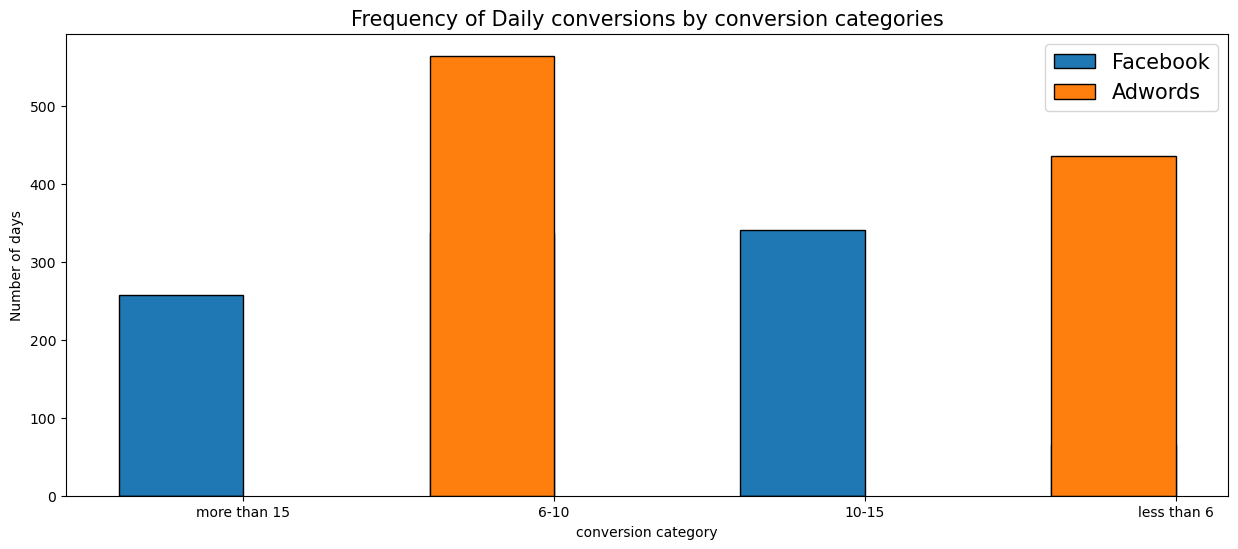

In [21]:
x_axis = np.arange(len(category_df))
plt.figure(figsize = (15,6))
plt.bar(x_axis - 0.2,category_df['count_x'],0.4,label = 'Facebook',linewidth = 1, edgecolor = 'k')
plt.bar(x_axis - 0.2,category_df['count_y'],0.4,label = 'Adwords',linewidth = 1, edgecolor = 'k')

plt.xticks(x_axis,category_df['category'])
plt.xlabel("conversion category")
plt.ylabel("Number of days")
plt.title("Frequency of Daily conversions by conversion categories",fontsize = 15)
plt.legend(fontsize =15)
plt.show()

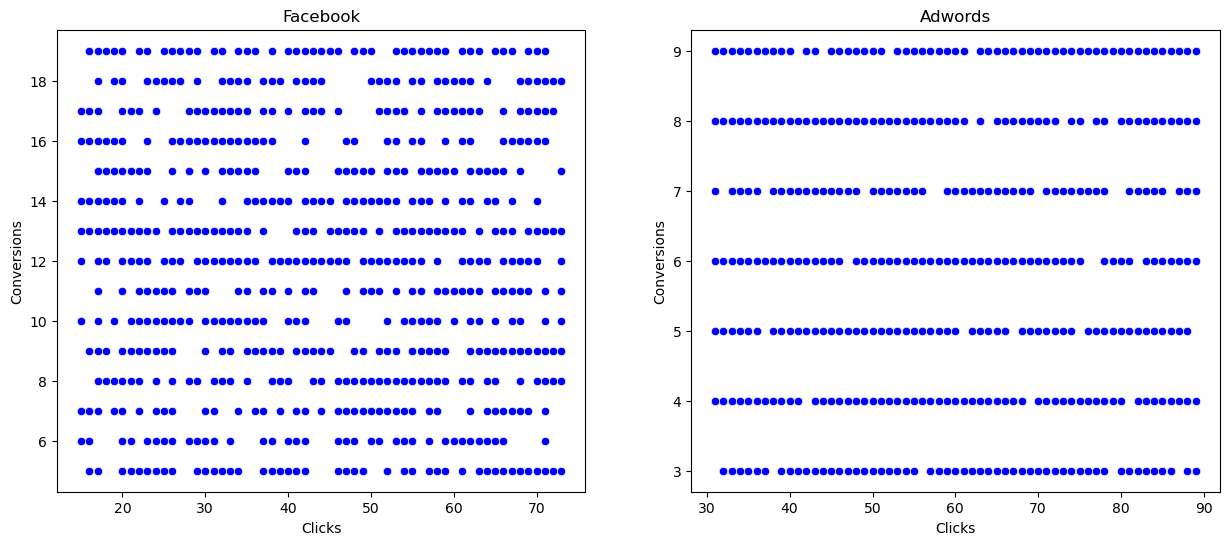

In [22]:
plt.figure(figsize =(15,6))
plt.subplot(1,2,1)
plt.title("Facebook")
sns.scatterplot(x=df["facebook_ad_clicks"],y = df["facebook_ad_conversions"],color = "Blue")
plt.xlabel('Clicks')
plt.ylabel("Conversions")
plt.subplot(1,2,2)
plt.title("Adwords")
sns.scatterplot(x=df["adword_ad_clicks"],y = df["adword_ad_conversions"],color = "Blue")
plt.xlabel("Clicks")
plt.ylabel("Conversions")
plt.show()

In [23]:
facebook_corr = df[["facebook_ad_conversions","facebook_ad_clicks"]].corr()
facebook_corr

,facebook_ad_conversions,facebook_ad_clicks
facebook_ad_conversions,1.000000,-0.005009
facebook_ad_clicks,-0.005009,1.000000


In [24]:
adwords_corr = df[["adword_ad_conversions","adword_ad_clicks"]].corr()
adwords_corr

,adword_ad_conversions,adword_ad_clicks
adword_ad_conversions,1.000000,0.004162
adword_ad_clicks,0.004162,1.000000


In [ ]:
# HYPOTHESIS TESTING

In [31]:
print("Mean Conversion \n---")
print("Facebook :" , round(df["facebook_ad_conversions"].mean(),2))
print("Adwords :" , round(df["adword_ad_conversions"].mean(),2))

# comparing the p value with the significance of 5% or 0.5
t_stats,p_value = st.ttest_ind(a = df["facebook_ad_conversions"],b = df["adword_ad_conversions"], equal_var = False)
print("\nT statistic", t_stats,"\np-value",p_value)
if p_value < 0.5:
    print("n\np-value is less than significance value, Reject the null hypothesis")
else:
    print("\np-value is greater than singnificance value, Accept the null hypothesis")

Mean Conversion 
---
Facebook : 11.98
Adwords : 5.93

T statistic 40.25906231407935 
p-value 6.886351887267426e-237
n
p-value is less than significance value, Reject the null hypothesis


In [41]:
# Regression Analysis
x = df[["facebook_ad_clicks"]]

# dependent variable
y = df[["facebook_ad_conversions"]]

# initializing and fitting Linear Regression model
model = LinearRegression()
model.fit(x,y)
prediction = model.predict(x)

# model evalution
r2 = r2_score(y, prediction)*100
mse = mean_squared_error(y,prediction)
print("Accuracy (R2 Score):" , round(r2,2),"%")
print("Mean Squared Error:", round(mse,2))

Accuracy (R2 Score): 0.0 %
Mean Squared Error: 18.46


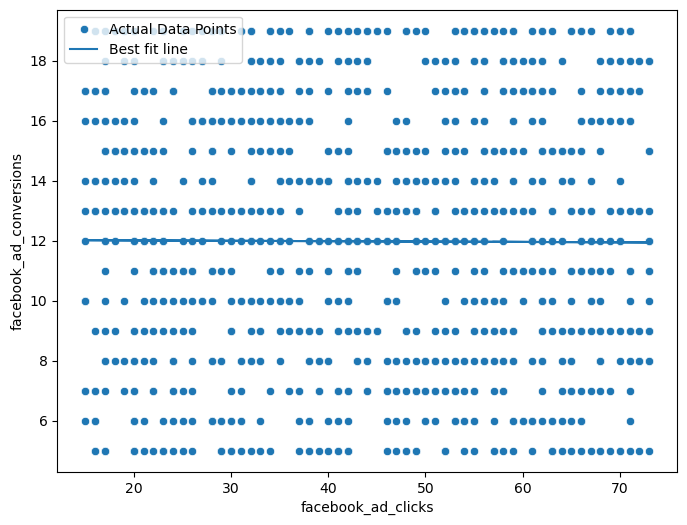

In [35]:
plt.figure(figsize = (8,6))
sns.scatterplot(x = df["facebook_ad_clicks"],y = df["facebook_ad_conversions"],label = "Actual Data Points")
plt.plot(df["facebook_ad_clicks"],prediction,label = "Best fit line")
plt.legend()
plt.show()

In [40]:
print(f" For {50} clicks, Expected Conversion : {round(model.predict([[50]])[0][0],2)}")
print(f" For {80} clicks, Expected Conversion : {round(model.predict([[80]])[0][0],2)}")


 For 50 clicks, Expected Conversion : 11.97
 For 80 clicks, Expected Conversion : 11.93
